In [ ]:
print("Future Interns - Machine Learning Task 1")
print("Sales and Demand Forecasting")

Future Interns - Machine Learning Task 1
Sales and Demand Forecasting


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

# Create sample monthly sales data
data = {
    "Month": pd.date_range(
        start="2024-01-01",
        periods=24,
        freq="MS"
    ),
    "Sales": [
        120, 135, 128, 145, 150, 160,
        155, 170, 180, 175, 190, 210,
        200, 215, 220, 230, 225, 245,
        250, 260, 255, 275, 285, 300
    ]
}

df = pd.DataFrame(data)

print(df.head())


       Month  Sales
0 2024-01-01    120
1 2024-02-01    135
2 2024-03-01    128
3 2024-04-01    145
4 2024-05-01    150


In [ ]:

# Check the dataset
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

# Remove duplicate rows and rows with missing values
df = df.drop_duplicates()
df = df.dropna(subset=["Month", "Sales"])

# Sort sales data by month
df = df.sort_values("Month").reset_index(drop=True)

print("\nCleaned dataset:")
print(df.head())


Dataset shape: (24, 2)

Missing values:
Month    0
Sales    0
dtype: int64

Cleaned dataset:
       Month  Sales
0 2024-01-01    120
1 2024-02-01    135
2 2024-03-01    128
3 2024-04-01    145
4 2024-05-01    150


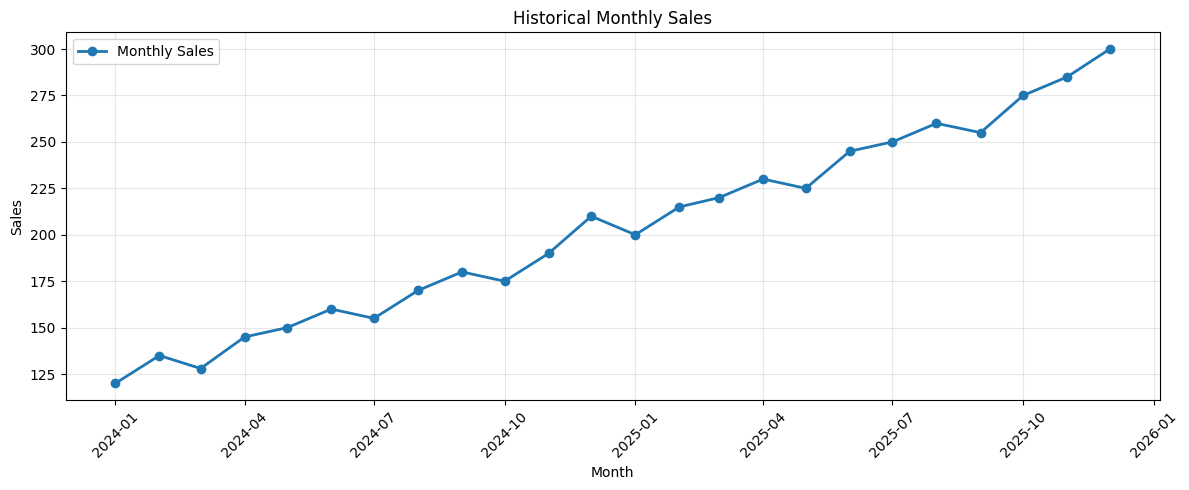

In [ ]:

# Plot historical monthly sales
plt.figure(figsize=(12, 5))

plt.plot(
    df["Month"],
    df["Sales"],
    marker="o",
    linewidth=2,
    label="Monthly Sales"
)

plt.title("Historical Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:

# Create a numerical time feature
df["Month_Number"] = np.arange(1, len(df) + 1)

# Use the first 20 months for training
# Use the last 4 months for testing
train = df.iloc[:20]
test = df.iloc[20:]

X_train = train[["Month_Number"]]
y_train = train["Sales"]

X_test = test[["Month_Number"]]
y_test = test["Sales"]

print("Training rows:", len(train))
print("Testing rows:", len(test))


Training rows: 20
Testing rows: 4


In [ ]:

# Create and train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict sales for the test months
test_predictions = model.predict(X_test)

print("Model trained successfully!")


Model trained successfully!


In [ ]:

# Calculate prediction errors
mae = mean_absolute_error(y_test, test_predictions)
rmse = np.sqrt(mean_squared_error(y_test, test_predictions))

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")

# Compare actual and predicted sales
results = pd.DataFrame({
    "Month": test["Month"].values,
    "Actual Sales": y_test.values,
    "Predicted Sales": np.round(test_predictions, 2)
})

print("\nActual vs Predicted Sales:")
print(results.to_string(index=False))


Mean Absolute Error (MAE): 8.94
Root Mean Squared Error (RMSE): 9.77

Actual vs Predicted Sales:
     Month  Actual Sales  Predicted Sales
2025-09-01           255           263.19
2025-10-01           275           270.34
2025-11-01           285           277.48
2025-12-01           300           284.63


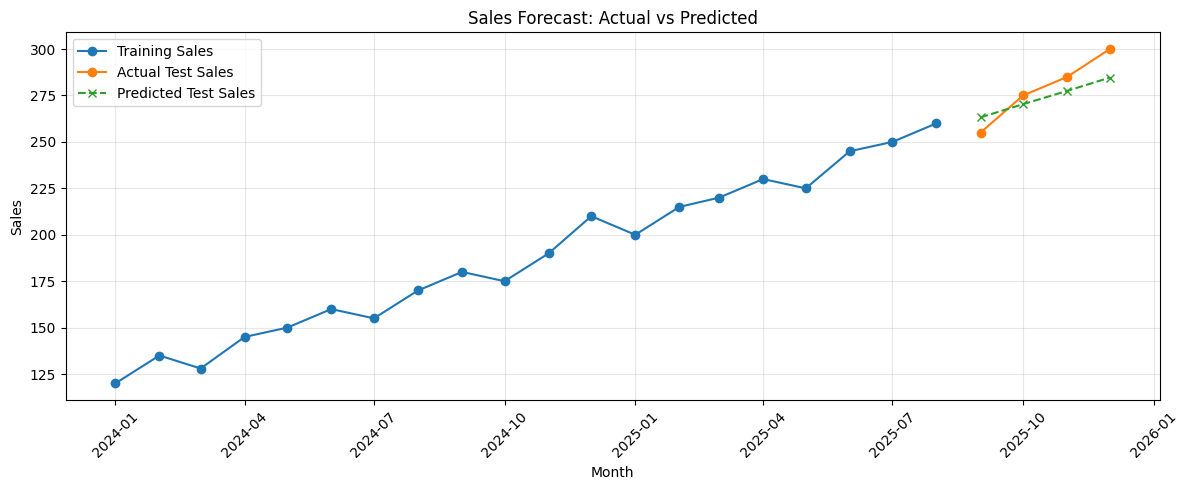

In [ ]:

plt.figure(figsize=(12, 5))

plt.plot(
    train["Month"], train["Sales"],
    label="Training Sales", marker="o"
)

plt.plot(
    test["Month"], y_test,
    label="Actual Test Sales", marker="o"
)

plt.plot(
    test["Month"], test_predictions,
    label="Predicted Test Sales", marker="x", linestyle="--"
)

plt.title("Sales Forecast: Actual vs Predicted")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:

# Forecast the next 3 months

future_months = pd.date_range(
    start=df["Month"].max() + pd.offsets.MonthBegin(1),
    periods=3,
    freq="MS"
)

future_df = pd.DataFrame({
    "Month": future_months,
    "Month_Number": np.arange(len(df) + 1, len(df) + 4)
})

future_df["Forecasted_Sales"] = model.predict(
    future_df[["Month_Number"]]
).round(2)

print("Next 3 Months Sales Forecast")
print(future_df.to_string(index=False))


Next 3 Months Sales Forecast
     Month  Month_Number  Forecasted_Sales
2026-01-01            25            291.78
2026-02-01            26            298.92
2026-03-01            27            306.07


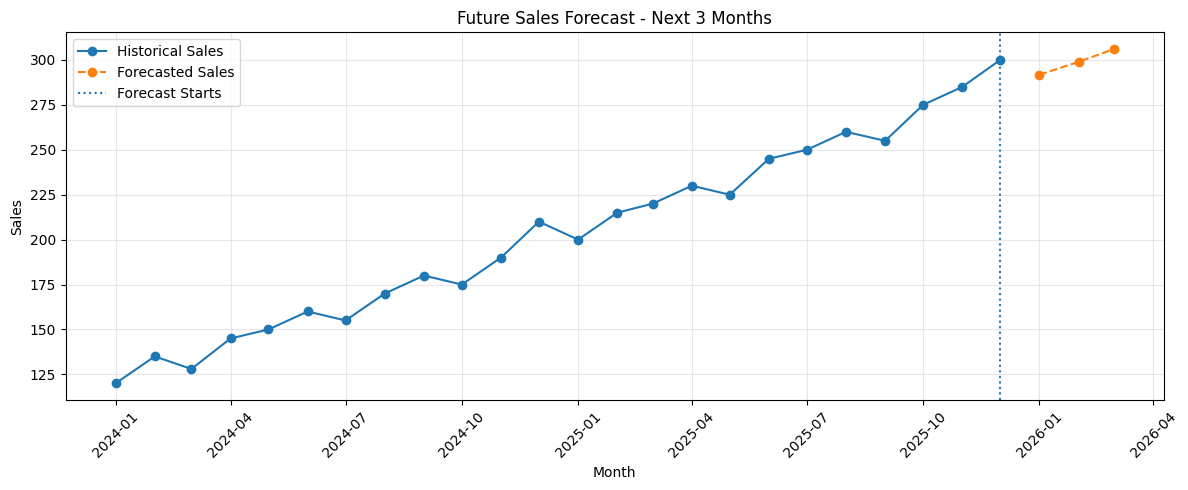

In [ ]:

plt.figure(figsize=(12, 5))

plt.plot(
    df["Month"], df["Sales"],
    marker="o", label="Historical Sales"
)

plt.plot(
    future_df["Month"], future_df["Forecasted_Sales"],
    marker="o", linestyle="--", label="Forecasted Sales"
)

plt.axvline(
    df["Month"].max(),
    linestyle=":", label="Forecast Starts"
)

plt.title("Future Sales Forecast - Next 3 Months")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import os

print(os.listdir("/content"))

['.config', 'retail_sales_dataset.csv', 'sample_data']


In [ ]:
df = pd.read_csv("/content/retail_sales_dataset.csv")

print(df.head())
print(df.columns.tolist())
print(df.shape)

   Transaction ID        Date Customer ID  Gender  Age Product Category  \
0               1  2023-11-24     CUST001    Male   34           Beauty   
1               2  2023-02-27     CUST002  Female   26         Clothing   
2               3  2023-01-13     CUST003    Male   50      Electronics   
3               4  2023-05-21     CUST004    Male   37         Clothing   
4               5  2023-05-06     CUST005    Male   30           Beauty   

   Quantity  Price per Unit  Total Amount  
0         3              50           150  
1         2             500          1000  
2         1              30            30  
3         1             500           500  
4         2              50           100  
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']
(1000, 9)


In [ ]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (1000, 9)

Column names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Data types:
Transaction ID       int64
Date                object
Customer ID         object
Gender              object
Age                  int64
Product Category    object
Quantity             int64
Price per Unit       int64
Total Amount         int64
dtype: object

Missing values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [ ]:
print(df.head(10).to_string(index=False))

 Transaction ID       Date Customer ID Gender  Age Product Category  Quantity  Price per Unit  Total Amount
              1 2023-11-24     CUST001   Male   34           Beauty         3              50           150
              2 2023-02-27     CUST002 Female   26         Clothing         2             500          1000
              3 2023-01-13     CUST003   Male   50      Electronics         1              30            30
              4 2023-05-21     CUST004   Male   37         Clothing         1             500           500
              5 2023-05-06     CUST005   Male   30           Beauty         2              50           100
              6 2023-04-25     CUST006 Female   45           Beauty         1              30            30
              7 2023-03-13     CUST007   Male   46         Clothing         2              25            50
              8 2023-02-22     CUST008   Male   30      Electronics         4              25           100
              9 2023-12-13  

In [ ]:
# Check dataset columns and size
print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())

# Convert Date to datetime format
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Remove duplicate transactions and missing values
df = df.drop_duplicates()
df = df.dropna(subset=["Date", "Total Amount"])

# Ensure sales amounts are numeric
df["Total Amount"] = pd.to_numeric(
    df["Total Amount"], errors="coerce"
)
df = df.dropna(subset=["Total Amount"])

print("\nCleaned dataset shape:", df.shape)
print("\nMissing values after cleaning:")
print(df[["Date", "Total Amount"]].isnull().sum())

print("\nCleaned data preview:")
print(df.head())

Dataset shape: (1000, 9)

Columns: ['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Cleaned dataset shape: (1000, 9)

Missing values after cleaning:
Date            0
Total Amount    0
dtype: int64

Cleaned data preview:
   Transaction ID       Date Customer ID  Gender  Age Product Category  \
0               1 2023-11-24     CUST001    Male   34           Beauty   
1               2 2023-02-27     CUST002  Female   26         Clothing   
2               3 2023-01-13     CUST003    Male   50      Electronics   
3               4 2023-05-21     CUST004    Male   37         Clothing   
4               5 2023-05-06     CUST005    Male   30           Beauty   

   Quantity  Price per Unit  Total Amount  
0         3              50           150  
1         2             500          1000  
2         1              30            30  
3         1             500           500  
4         2              50          

In [ ]:
# Sort transactions by date
df = df.sort_values("Date")

# Calculate total sales for each month
monthly_sales = (
    df.set_index("Date")["Total Amount"]
      .resample("MS")
      .sum()
      .reset_index()
)

monthly_sales.columns = ["Month", "Sales"]

print(monthly_sales.to_string(index=False))

     Month  Sales
2023-01-01  35450
2023-02-01  44060
2023-03-01  28990
2023-04-01  33870
2023-05-01  53150
2023-06-01  36715
2023-07-01  35465
2023-08-01  36960
2023-09-01  23620
2023-10-01  46580
2023-11-01  34920
2023-12-01  44690
2024-01-01   1530


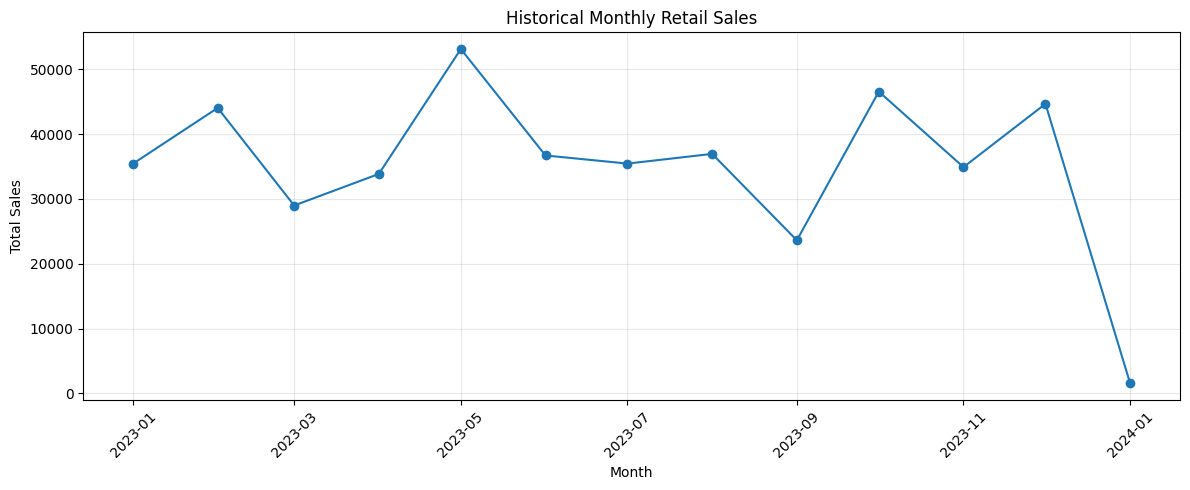

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales["Month"],
    monthly_sales["Sales"],
    marker="o"
)

plt.title("Historical Monthly Retail Sales")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Check the number of transactions in each month
df["Month"] = df["Date"].dt.to_period("M")

monthly_check = df.groupby("Month").agg(
    Transaction_Count=("Transaction ID", "count"),
    Total_Sales=("Total Amount", "sum")
).reset_index()

print(monthly_check.to_string(index=False))

  Month  Transaction_Count  Total_Sales
2023-01                 76        35450
2023-02                 85        44060
2023-03                 73        28990
2023-04                 86        33870
2023-05                105        53150
2023-06                 77        36715
2023-07                 72        35465
2023-08                 94        36960
2023-09                 65        23620
2023-10                 96        46580
2023-11                 78        34920
2023-12                 91        44690
2024-01                  2         1530


In [ ]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Create a fresh monthly dataset
sales = monthly_sales.copy()
sales["Month"] = pd.to_datetime(sales["Month"])
sales = sales.sort_values("Month").reset_index(drop=True)

# Use the month sequence as a feature
sales["Month_Number"] = np.arange(1, len(sales) + 1)

# Keep the last 3 months for testing
train = sales.iloc[:-3]
test = sales.iloc[-3:]

X_train = train[["Month_Number"]]
y_train = train["Sales"]

X_test = test[["Month_Number"]]
y_test = test["Sales"]

# Train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict the test months
predictions = model.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))

results = pd.DataFrame({
    "Month": test["Month"].dt.strftime("%Y-%m"),
    "Actual Sales": y_test.values,
    "Predicted Sales": np.round(predictions, 2)
})

print("\nActual vs Predicted Sales:")
print(results.to_string(index=False))

Mean Absolute Error (MAE): 15048.84
Root Mean Squared Error (RMSE): 20897.28

Actual vs Predicted Sales:
  Month  Actual Sales  Predicted Sales
2023-11         34920         36995.67
2023-12         44690         36906.52
2024-01          1530         36817.36


In [22]:
# Generate the next 3 months
last_month = sales["Month"].max()

future_months = pd.date_range(
    start=last_month + pd.offsets.MonthBegin(1),
    periods=3,
    freq="MS"
)

future_df = pd.DataFrame({
    "Month": future_months,
    "Month_Number": np.arange(
        len(sales) + 1,
        len(sales) + 4
    )
})

# Predict future sales
future_df["Forecasted_Sales"] = model.predict(
    future_df[["Month_Number"]]
).round(2)

print("Sales Forecast for the Next 3 Months")
print(future_df.to_string(index=False))

Sales Forecast for the Next 3 Months
     Month  Month_Number  Forecasted_Sales
2024-02-01            14          36728.21
2024-03-01            15          36639.06
2024-04-01            16          36549.91


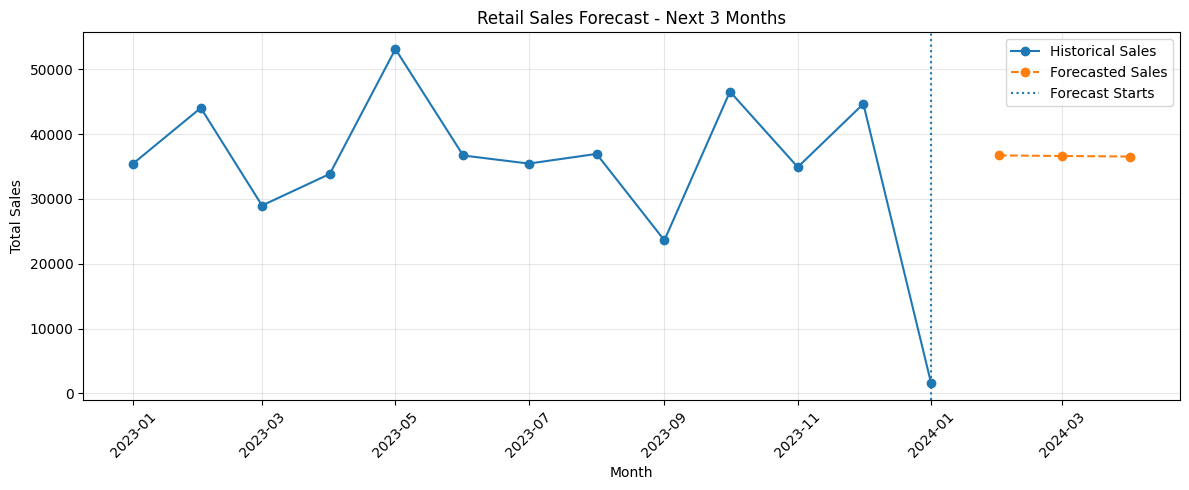

In [23]:
plt.figure(figsize=(12, 5))

plt.plot(
    sales["Month"],
    sales["Sales"],
    marker="o",
    label="Historical Sales"
)

plt.plot(
    future_df["Month"],
    future_df["Forecasted_Sales"],
    marker="o",
    linestyle="--",
    label="Forecasted Sales"
)

plt.axvline(
    sales["Month"].max(),
    linestyle=":",
    label="Forecast Starts"
)

plt.title("Retail Sales Forecast - Next 3 Months")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [24]:
df["Month"] = df["Date"].dt.to_period("M")

monthly_check = df.groupby("Month").agg(
    Transaction_Count=("Transaction ID", "count"),
    Total_Sales=("Total Amount", "sum")
).reset_index()

print(monthly_check.to_string(index=False))

  Month  Transaction_Count  Total_Sales
2023-01                 76        35450
2023-02                 85        44060
2023-03                 73        28990
2023-04                 86        33870
2023-05                105        53150
2023-06                 77        36715
2023-07                 72        35465
2023-08                 94        36960
2023-09                 65        23620
2023-10                 96        46580
2023-11                 78        34920
2023-12                 91        44690
2024-01                  2         1530


In [25]:
# Keep only complete months: January to December 2023
sales = monthly_sales[
    monthly_sales["Month"] < "2024-01-01"
].copy()

sales = sales.sort_values("Month").reset_index(drop=True)

print("Monthly sales used for forecasting:")
print(sales.to_string(index=False))

print("\nNumber of complete months:", len(sales))

Monthly sales used for forecasting:
     Month  Sales
2023-01-01  35450
2023-02-01  44060
2023-03-01  28990
2023-04-01  33870
2023-05-01  53150
2023-06-01  36715
2023-07-01  35465
2023-08-01  36960
2023-09-01  23620
2023-10-01  46580
2023-11-01  34920
2023-12-01  44690

Number of complete months: 12


In [26]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

sales["Month_Number"] = np.arange(1, len(sales) + 1)

# Use the first 9 months for training and last 3 for testing
train = sales.iloc[:-3]
test = sales.iloc[-3:]

X_train = train[["Month_Number"]]
y_train = train["Sales"]

X_test = test[["Month_Number"]]
y_test = test["Sales"]

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

results = pd.DataFrame({
    "Month": test["Month"].dt.strftime("%Y-%m"),
    "Actual Sales": y_test.values,
    "Predicted Sales": np.round(predictions, 2)
})

print("\nActual vs Predicted Sales:")
print(results.to_string(index=False))

MAE: 10870.28
RMSE: 11986.63

Actual vs Predicted Sales:
  Month  Actual Sales  Predicted Sales
2023-10         46580         32073.47
2023-11         34920         31193.06
2023-12         44690         30312.64


In [27]:
future_months = pd.date_range(
    start=sales["Month"].max() + pd.offsets.MonthBegin(1),
    periods=3,
    freq="MS"
)

future_df = pd.DataFrame({
    "Month": future_months,
    "Month_Number": np.arange(len(sales) + 1, len(sales) + 4)
})

future_df["Forecasted_Sales"] = model.predict(
    future_df[["Month_Number"]]
).round(2)

print(future_df.to_string(index=False))

     Month  Month_Number  Forecasted_Sales
2024-01-01            13          29432.22
2024-02-01            14          28551.81
2024-03-01            15          27671.39


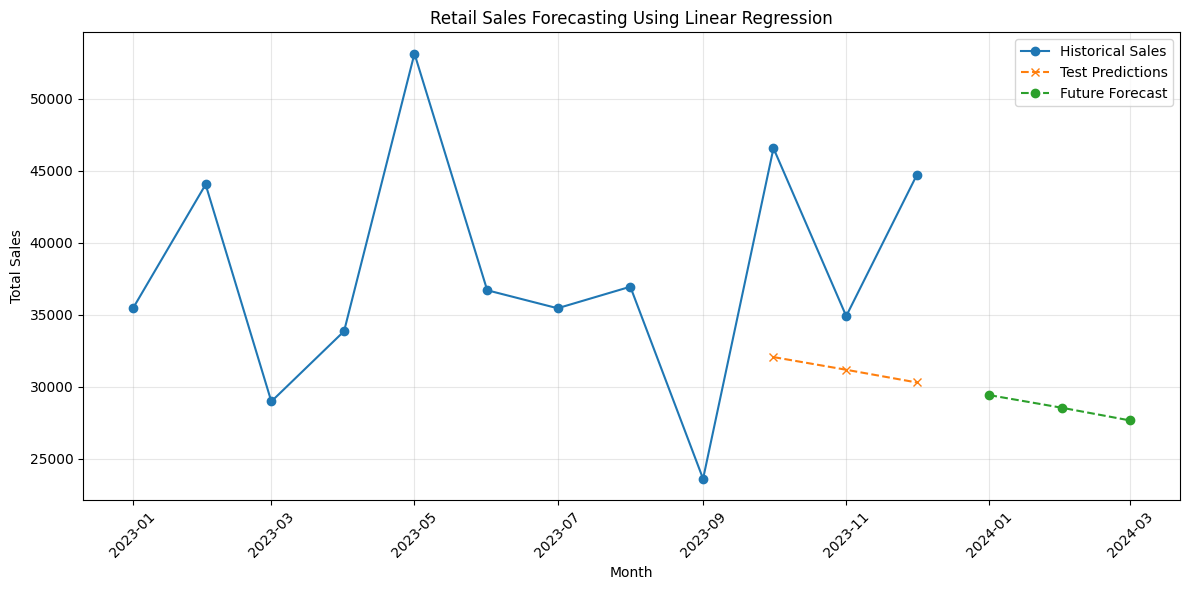

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    sales["Month"], sales["Sales"],
    marker="o", label="Historical Sales"
)

plt.plot(
    test["Month"], predictions,
    marker="x", linestyle="--",
    label="Test Predictions"
)

plt.plot(
    future_df["Month"], future_df["Forecasted_Sales"],
    marker="o", linestyle="--",
    label="Future Forecast"
)

plt.title("Retail Sales Forecasting Using Linear Regression")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Conclusion

This project developed a basic retail sales forecasting model using Python and a Kaggle retail sales dataset.

The transaction data was cleaned and aggregated into monthly sales totals. Linear Regression was trained on the first nine months of complete data, and the final three months were used to evaluate its performance.

The model achieved a Mean Absolute Error (MAE) of 10,870.28 and a Root Mean Squared Error (RMSE) of 11,986.63. It was then used to generate forecasts for January, February, and March 2024.

The results demonstrate how machine learning can support basic sales trend analysis. However, the limited dataset and relatively large prediction errors mean that further improvements and testing are needed before the model can be used for real business decisions.

### Tools and Technologies
- Python
- Google Colab
- Pandas and NumPy
- Matplotlib
- Scikit-learn
- Linear Regression

### Limitation
The model uses only 12 complete monthly observations and a simple time-based feature. More historical data, seasonal features, and comparisons with other forecasting models could improve its performance.